# 23 — Hotspot Anomaly Problem Formulation
## Emerging ≠ Anomalous

### Research question
**Apakah hotspot Emerging-3 juga cenderung tidak terduga oleh kondisi lingkungan dan histori kebakaran?**

Notebook ini belum membuat GeoMAE. Tujuannya adalah membangun definisi anomaly yang defensible sebelum masked self-supervised learning.

- **Emerging-3**: `target_fire_active_t1 = 1` dan `active_days_prev3_incl_t = 0`.
- **Anomalous hotspot candidate**: actual hotspot pada `t+1` yang mendapat expectedness score rendah dari informasi yang tersedia sampai `t`.

### Batas interpretasi
Output notebook ini **bukan** label natural, anthropogenic, intentional burning, pembukaan lahan, sawit, atau ilegal.

### Development discipline
- Train: 2026-05-08 → 2026-07-31
- Development evaluation: August 2026
- September tidak dipakai untuk mendesain anomaly definition.

In [15]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 260)
RANDOM_STATE = 42

In [16]:
# Resolve project paths
cwd = Path.cwd()
candidates = [cwd, cwd.parent, Path('/content/skripsi-karhut'), Path('/content/drive/MyDrive/skripsi-karhut')]
PROJECT_ROOT = None
for root in candidates:
    p = root/'data'/'processed'/'regional_025'/'karhut_ml_dataset_regional_025.csv'
    if p.exists():
        PROJECT_ROOT = root; break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the skripsi-karhut project root or set PROJECT_ROOT manually.')

DATA_PATH = PROJECT_ROOT/'data'/'processed'/'regional_025'/'karhut_ml_dataset_regional_025.csv'
LOCK_PATH = PROJECT_ROOT/'model_results'/'regional_025_dataset'/'exports'/'regional_domain_lock_train_only.json'
REGION_ID = 'T2'
if LOCK_PATH.exists():
    REGION_ID = str(json.loads(LOCK_PATH.read_text(encoding='utf-8')).get('candidate_id', REGION_ID))

RESULTS_DIR = PROJECT_ROOT/'model_results'/'hotspot_anomaly_problem_formulation'/REGION_ID.lower()
FIGURES_DIR = RESULTS_DIR/'figures'; EXPORT_DIR = RESULTS_DIR/'exports'
for p in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]: p.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_PATH   :', DATA_PATH)
print('REGION      :', REGION_ID)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH   : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
REGION      : T2


In [17]:
# Load regional dataset
regional = pd.read_csv(DATA_PATH, parse_dates=['date'])
print('Rows :', len(regional))
print('Dates:', regional['date'].min().date(), '→', regional['date'].max().date())
print('Nodes:', regional['cell_id'].nunique())
display(regional.head())

Rows : 16625
Dates: 2026-05-08 → 2026-09-09
Nodes: 133


,date,cell_id,fire_count,frp_sum,fire_active,node_index,grid_lat,grid_lon,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,frp_sum_roll3,fire_count_roll7,frp_sum_roll7,target_fire_active_t1,active_days_prev3_incl_t,event_type_3d,active_days_prev7_incl_t,event_type_7d,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,boundary_layer_height_mean,vapour_pressure_deficit_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean
0,2026-05-08,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.275000,30.5,91.458333,15.4,238.750000,0.317917,3.929167,5.6,0.691170,-1.995124
1,2026-05-09,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.2,90.250000,8.2,214.166667,0.386250,3.108333,5.1,0.868119,1.602951
2,2026-05-10,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.941667,31.6,89.875000,2.2,175.625000,0.405833,4.250000,7.0,-2.669541,1.563219
3,2026-05-11,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,28.187500,34.2,83.541667,2.3,420.208333,0.734167,3.991667,6.6,-0.189994,1.040999
4,2026-05-12,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.4,88.416667,6.2,271.041667,0.471250,3.854167,5.4,1.313670,1.731916


In [18]:
# Locked feature definitions from NB17/NB18
FIRE_HISTORY_FEATURES = [
    'fire_count_lag1','fire_count_lag3','fire_count_lag7',
    'frp_sum_lag1','frp_sum_lag3','frp_sum_lag7',
    'fire_count_roll3','fire_count_roll7','frp_sum_roll3','frp_sum_roll7'
]
WEATHER_FEATURES = [
    'temperature_mean','temperature_max','relative_humidity_mean','precipitation_sum',
    'boundary_layer_height_mean','vapour_pressure_deficit_mean',
    'wind_speed_mean','wind_speed_max','wind_u_mean','wind_v_mean'
]
CURRENT_DAY_FIRE_FEATURES = ['fire_active','fire_count','frp_sum']
ENV10 = WEATHER_FEATURES
FIRE13 = CURRENT_DAY_FIRE_FEATURES + FIRE_HISTORY_FEATURES
CTX23 = FIRE13 + WEATHER_FEATURES
TARGET = 'target_fire_active_t1'

required = ['date','cell_id','grid_lat','grid_lon','active_days_prev3_incl_t','event_type_3d',TARGET] + CTX23
missing = sorted(set(required)-set(regional.columns))
if missing: raise ValueError(f'Missing required columns: {missing}')
print('ENV10:', len(ENV10), '| FIRE13:', len(FIRE13), '| CTX23:', len(CTX23))

ENV10: 10 | FIRE13: 13 | CTX23: 23


In [19]:
# Development split — September excluded
TRAIN_START, TRAIN_END = pd.Timestamp('2026-05-08'), pd.Timestamp('2026-07-31')
VAL_START, VAL_END = pd.Timestamp('2026-08-01'), pd.Timestamp('2026-08-31')
model_data = regional[regional[CTX23+[TARGET]].notna().all(axis=1)].copy()
train = model_data[model_data['date'].between(TRAIN_START, TRAIN_END)].copy()
val = model_data[model_data['date'].between(VAL_START, VAL_END)].copy()
september = model_data[model_data['date'] > VAL_END].copy()
print('Train     :', len(train), train['date'].min().date(), '→', train['date'].max().date())
print('Validation:', len(val), val['date'].min().date(), '→', val['date'].max().date())
print('September :', len(september), '(excluded from NB23 development)')
assert train['date'].max() < val['date'].min()

Train     : 11305 2026-05-08 → 2026-07-31
Validation: 4123 2026-08-01 → 2026-08-31
September : 1197 (excluded from NB23 development)


In [20]:
# Event composition audit
def summarize(df, name):
    return {
        'Split':name,'Rows':len(df),'Dates':df['date'].nunique(),'Nodes':df['cell_id'].nunique(),
        'Positives':int(df[TARGET].sum()),'Positive rate':float(df[TARGET].mean()),
        'Emerging-3 positives':int((df[TARGET].eq(1)&df['active_days_prev3_incl_t'].eq(0)).sum()),
        'Persistent positives':int((df[TARGET].eq(1)&df['active_days_prev3_incl_t'].gt(0)).sum())
    }
development_summary = pd.DataFrame([summarize(train,'Train'), summarize(val,'August validation')])
display(development_summary)

,Split,Rows,Dates,Nodes,Positives,Positive rate,Emerging-3 positives,Persistent positives
0,Train,11305,85,133,833,0.073684,314,519
1,August validation,4123,31,133,2169,0.526073,224,1945


# PART A — Expectedness baselines
Kita membuat tiga model sederhana:
- **ENV10**: weather only → environmental expectedness.
- **FIRE13**: current fire + fire history → fire-history expectedness.
- **CTX23**: weather + current fire + history → contextual expectedness.

Karena Logistic Regression menggunakan `class_weight="balanced"`, output `predict_proba` diperlakukan sebagai **expectedness score**, bukan calibrated probability.

In [21]:
def build_lr():
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))
    ])
def fit_model(features):
    m=build_lr(); m.fit(train[features], train[TARGET]); return m

def metric_bundle(y, s):
    y=np.asarray(y); s=np.asarray(s)
    return {
        'Rows':len(y),'Positives':int(y.sum()),'Prevalence':float(y.mean()),
        'PR-AUC':float(average_precision_score(y,s)),
        'ROC-AUC':float(roc_auc_score(y,s)) if len(np.unique(y))==2 else np.nan
    }

env_model, fire_model, ctx_model = fit_model(ENV10), fit_model(FIRE13), fit_model(CTX23)
print('Models fitted on May–July only.')

Models fitted on May–July only.


In [22]:
# August expectedness scores
val_scored = val.copy()
val_scored['env_expectedness'] = env_model.predict_proba(val_scored[ENV10])[:,1]
val_scored['fire_expectedness'] = fire_model.predict_proba(val_scored[FIRE13])[:,1]
val_scored['ctx_expectedness'] = ctx_model.predict_proba(val_scored[CTX23])[:,1]
display(val_scored[['date','cell_id',TARGET,'event_type_3d','env_expectedness','fire_expectedness','ctx_expectedness']].head())

,date,cell_id,target_fire_active_t1,event_type_3d,env_expectedness,fire_expectedness,ctx_expectedness
85,2026-08-01,regional025_10_22,0,Negative,0.524814,0.294872,0.317596
86,2026-08-02,regional025_10_22,0,Negative,0.668676,0.294872,0.408260
87,2026-08-03,regional025_10_22,0,Negative,0.661600,0.294872,0.525194
88,2026-08-04,regional025_10_22,1,Emerging,0.578717,0.294872,0.549485
89,2026-08-05,regional025_10_22,1,Persistent,0.693405,0.789134,0.902353


In [23]:
# Overall + subgroup performance
rows=[]
for model_name, score_col in [('ENV10','env_expectedness'),('FIRE13','fire_expectedness'),('CTX23','ctx_expectedness')]:
    rows.append({'Model':model_name,'Context':'Overall',**metric_bundle(val_scored[TARGET],val_scored[score_col])})
    em = val_scored['active_days_prev3_incl_t'].eq(0)
    rows.append({'Model':model_name,'Context':'Emerging-3 eligible',**metric_bundle(val_scored.loc[em,TARGET],val_scored.loc[em,score_col])})
    rows.append({'Model':model_name,'Context':'Persistent-context',**metric_bundle(val_scored.loc[~em,TARGET],val_scored.loc[~em,score_col])})
expectedness_metrics = pd.DataFrame(rows)
display(expectedness_metrics)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC
0,ENV10,Overall,4123,2169,0.526073,0.594208,0.581621
1,ENV10,Emerging-3 eligible,1241,224,0.180500,0.180150,0.496106
2,ENV10,Persistent-context,2882,1945,0.674879,0.732253,0.580831
3,FIRE13,Overall,4123,2169,0.526073,0.877455,0.858476
4,FIRE13,Emerging-3 eligible,1241,224,0.180500,0.277072,0.649198
5,FIRE13,Persistent-context,2882,1945,0.674879,0.909001,0.828667
6,CTX23,Overall,4123,2169,0.526073,0.876138,0.849698
7,CTX23,Emerging-3 eligible,1241,224,0.180500,0.229095,0.563668
8,CTX23,Persistent-context,2882,1945,0.674879,0.909572,0.829706


# PART B — Positive-event anomaly ranking
Anomaly hanya dihitung untuk actual positive hotspot events (`target_fire_active_t1=1`).

- expectedness tinggi → lebih sesuai pola yang dipelajari
- expectedness rendah → lebih surprising
- **anomaly rank mendekati 1** → termasuk positive event paling tidak expected

Primary score dibuat rank-based agar tidak menyebut score Logistic Regression sebagai probabilitas anomaly yang terkalibrasi.

In [24]:
aug_pos = val_scored[val_scored[TARGET].eq(1)].copy()
aug_pos['event_date'] = aug_pos['date'] + pd.Timedelta(days=1)
for prefix in ['env','fire','ctx']:
    sc=f'{prefix}_expectedness'; rc=f'{prefix}_anomaly_rank'
    aug_pos[rc] = aug_pos[sc].rank(pct=True, ascending=False, method='average')
    aug_pos[f'{prefix}_anomaly_raw'] = 1-aug_pos[sc]
aug_pos['consensus_anomaly_rank'] = aug_pos[['env_anomaly_rank','fire_anomaly_rank','ctx_anomaly_rank']].mean(axis=1)
aug_pos['is_emerging3'] = aug_pos['active_days_prev3_incl_t'].eq(0)
aug_pos['research_group'] = np.where(aug_pos['is_emerging3'],'Emerging-3','Persistent')
print('August positive events:',len(aug_pos))
print('Emerging-3:',int(aug_pos['is_emerging3'].sum()),'| Persistent:',int((~aug_pos['is_emerging3']).sum()))

August positive events: 2169
Emerging-3: 224 | Persistent: 1945


In [25]:
# Core question: is Emerging-3 more anomalous?
anomaly_summary = (aug_pos.groupby('research_group').agg(
    events=('cell_id','size'),
    env_anomaly_mean=('env_anomaly_rank','mean'), env_anomaly_median=('env_anomaly_rank','median'),
    fire_anomaly_mean=('fire_anomaly_rank','mean'), fire_anomaly_median=('fire_anomaly_rank','median'),
    ctx_anomaly_mean=('ctx_anomaly_rank','mean'), ctx_anomaly_median=('ctx_anomaly_rank','median'),
    consensus_mean=('consensus_anomaly_rank','mean'), consensus_median=('consensus_anomaly_rank','median')
).reset_index())
display(anomaly_summary)

,research_group,events,env_anomaly_mean,env_anomaly_median,fire_anomaly_mean,fire_anomaly_median,ctx_anomaly_mean,ctx_anomaly_median,consensus_mean,consensus_median
0,Emerging-3,224,0.596971,0.621254,0.930899,0.948133,0.918490,0.930152,0.815454,0.830913
1,Persistent,1945,0.489089,0.483633,0.450632,0.448594,0.452061,0.448594,0.463927,0.451514


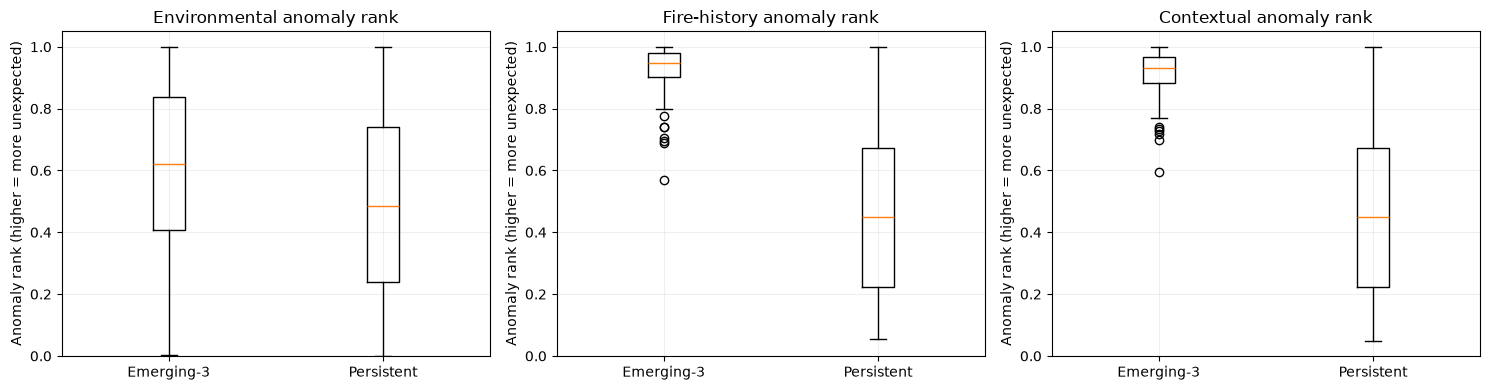

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\figures\01_emerging_vs_persistent_anomaly_rank.png


In [26]:
# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in [
    (axes[0], 'env_anomaly_rank', 'Environmental anomaly rank'),
    (axes[1], 'fire_anomaly_rank', 'Fire-history anomaly rank'),
    (axes[2], 'ctx_anomaly_rank', 'Contextual anomaly rank')
]:
    groups = [
        aug_pos.loc[
            aug_pos['research_group'].eq(g),
            col
        ].dropna().to_numpy()
        for g in ['Emerging-3', 'Persistent']
    ]

    ax.boxplot(
        groups,
        tick_labels=['Emerging-3', 'Persistent']
    )

    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Anomaly rank (higher = more unexpected)')
    ax.set_title(title)
    ax.grid(alpha=0.2)

plt.tight_layout()

path = FIGURES_DIR / '01_emerging_vs_persistent_anomaly_rank.png'
plt.savefig(path, dpi=190, bbox_inches='tight')
plt.show()

print('Saved:', path)

In [27]:
# Exploratory overlap: top 20% anomaly, NOT a final threshold
EXPLORATORY_HIGH_ANOMALY_Q=0.80
aug_pos['high_anomaly_exploratory'] = aug_pos['consensus_anomaly_rank'] >= EXPLORATORY_HIGH_ANOMALY_Q
display(pd.crosstab(aug_pos['research_group'],aug_pos['high_anomaly_exploratory'],margins=True))
display(aug_pos.groupby('research_group')['high_anomaly_exploratory'].mean().rename('Share in exploratory top-20% anomaly').reset_index())
print('Do not interpret this as anthropogenic classification.')

high_anomaly_exploratory,False,True,All
research_group,,,
Emerging-3,92,132,224
Persistent,1823,122,1945
All,1915,254,2169


,research_group,Share in exploratory top-20% anomaly
0,Emerging-3,0.589286
1,Persistent,0.062725


Do not interpret this as anthropogenic classification.


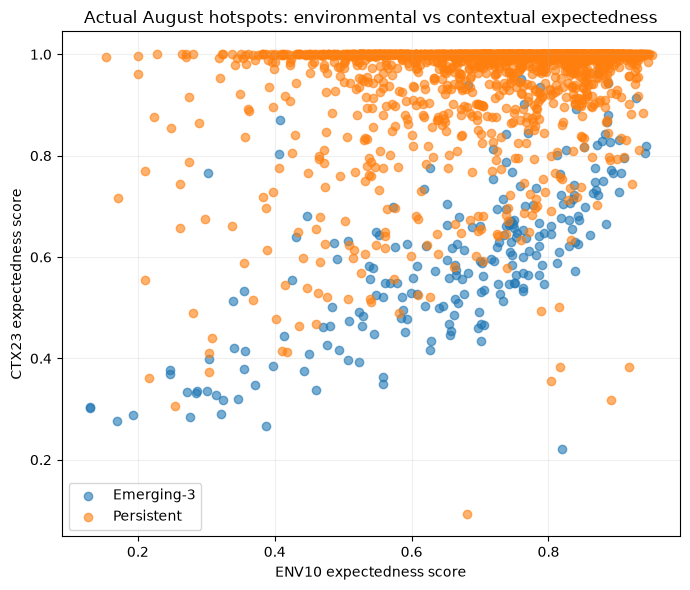

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\figures\02_environmental_vs_contextual_expectedness.png


In [28]:
# Environmental vs contextual expectedness
fig,ax=plt.subplots(figsize=(7,6))
for group,sub in aug_pos.groupby('research_group'):
    ax.scatter(sub['env_expectedness'],sub['ctx_expectedness'],alpha=.6,label=group)
ax.set_xlabel('ENV10 expectedness score'); ax.set_ylabel('CTX23 expectedness score')
ax.set_title('Actual August hotspots: environmental vs contextual expectedness'); ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); path=FIGURES_DIR/'02_environmental_vs_contextual_expectedness.png'; plt.savefig(path,dpi=190,bbox_inches='tight'); plt.show(); print('Saved:',path)

### Conceptual interpretation
- ENV high + CTX high → relatively expected.
- ENV low + CTX high → weather kurang menjelaskan, tetapi local fire context menjelaskan.
- ENV high + CTX low → environment mendukung tetapi local context masih tidak biasa.
- ENV low + CTX low → kandidat paling menarik sebagai **contextually anomalous hotspot**.

Tetap: **anomalous ≠ anthropogenic**.

In [29]:
# Top anomaly candidates
TOP_K=25
top_anomalies=(aug_pos.sort_values(['consensus_anomaly_rank','ctx_anomaly_rank','env_anomaly_rank'],ascending=False).head(TOP_K).copy())
candidate_columns=['event_date','date','cell_id','grid_lat','grid_lon','research_group','fire_active','fire_count','frp_sum','active_days_prev3_incl_t','temperature_mean','temperature_max','relative_humidity_mean','precipitation_sum','vapour_pressure_deficit_mean','wind_speed_mean','env_expectedness','fire_expectedness','ctx_expectedness','env_anomaly_rank','fire_anomaly_rank','ctx_anomaly_rank','consensus_anomaly_rank']
display(top_anomalies[candidate_columns])

,event_date,date,cell_id,grid_lat,grid_lon,research_group,fire_active,fire_count,frp_sum,active_days_prev3_incl_t,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,vapour_pressure_deficit_mean,wind_speed_mean,env_expectedness,fire_expectedness,ctx_expectedness,env_anomaly_rank,fire_anomaly_rank,ctx_anomaly_rank,consensus_anomaly_rank
15089,2026-08-06,2026-08-05,regional025_8_34,-2.375,116.625,Emerging-3,0,0.0,0.0,0.0,27.758333,28.0,77.416667,0.0,0.835833,21.720833,0.272188,0.294872,0.334307,0.989857,0.979023,0.993084,0.987321
15108,2026-08-25,2026-08-24,regional025_8_34,-2.375,116.625,Emerging-3,0,0.0,0.0,0.0,27.400000,27.8,75.916667,0.0,0.880417,25.779167,0.247164,0.294872,0.377340,0.994006,0.979023,0.987552,0.986860
13463,2026-08-05,2026-08-04,regional025_7_33,-2.625,116.375,Emerging-3,0,0.0,0.0,0.0,27.737500,29.7,77.666667,0.0,0.846667,16.895833,0.284608,0.294872,0.331791,0.987091,0.979023,0.993545,0.986553
4592,2026-08-09,2026-08-08,regional025_12_34,-1.375,116.625,Emerging-3,0,0.0,0.0,0.0,27.825000,30.4,76.875000,0.0,0.891250,13.087500,0.286644,0.294872,0.335745,0.986630,0.979023,0.992162,0.985938
11839,2026-08-06,2026-08-05,regional025_6_32,-2.875,116.125,Emerging-3,0,0.0,0.0,0.0,27.366667,30.3,78.875000,0.0,0.808333,11.125000,0.321433,0.294872,0.291082,0.981097,0.979023,0.997234,0.985785
10463,2026-08-05,2026-08-04,regional025_5_32,-3.125,116.125,Emerging-3,0,0.0,0.0,0.0,27.862500,30.2,78.833333,0.0,0.826667,11.933333,0.301629,0.294872,0.334862,0.985247,0.979023,0.992623,0.985631
11972,2026-08-14,2026-08-13,regional025_6_33,-2.875,116.375,Emerging-3,0,0.0,0.0,0.0,27.875000,28.1,77.541667,0.0,0.843333,19.962500,0.314278,0.294872,0.327627,0.982480,0.979023,0.994006,0.985170
16591,2026-08-08,2026-08-07,regional025_9_33,-2.125,116.375,Emerging-3,0,0.0,0.0,0.0,27.645833,29.9,74.708333,0.0,0.958750,16.737500,0.324720,0.294872,0.317481,0.980175,0.979023,0.994929,0.984709
5473,2026-08-15,2026-08-14,regional025_13_28,-1.125,115.125,Emerging-3,0,0.0,0.0,0.0,28.591667,34.4,73.333333,0.3,1.190833,3.441667,0.386562,0.294872,0.267045,0.965883,0.979023,0.999078,0.981328
11976,2026-08-18,2026-08-17,regional025_6_33,-2.875,116.375,Emerging-3,0,0.0,0.0,0.0,27.516667,28.1,77.208333,0.0,0.840000,19.370833,0.169965,0.341677,0.275899,0.998617,0.942831,0.998617,0.980022


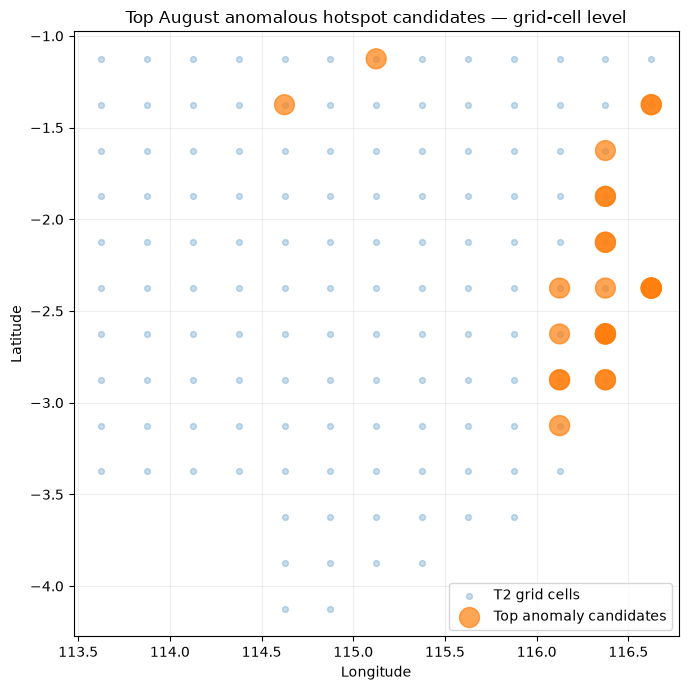

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\figures\03_top_anomaly_candidates_map.png


In [30]:
# Spatial view — grid-cell level, not precise FIRMS-point attribution
fig,ax=plt.subplots(figsize=(8,7))
all_nodes=val_scored[['cell_id','grid_lon','grid_lat']].drop_duplicates()
ax.scatter(all_nodes['grid_lon'],all_nodes['grid_lat'],s=18,alpha=.25,label='T2 grid cells')
sizes=30+180*top_anomalies['consensus_anomaly_rank'].to_numpy()
ax.scatter(top_anomalies['grid_lon'],top_anomalies['grid_lat'],s=sizes,alpha=.7,label='Top anomaly candidates')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_title('Top August anomalous hotspot candidates — grid-cell level')
ax.set_aspect('equal',adjustable='box'); ax.grid(alpha=.2); ax.legend(); plt.tight_layout()
path=FIGURES_DIR/'03_top_anomaly_candidates_map.png'; plt.savefig(path,dpi=190,bbox_inches='tight'); plt.show(); print('Saved:',path)

# PART C — What we still cannot infer
Dengan FIRMS + weather + fire history saja kita **belum bisa menentukan ignition source**.

Untuk tahap berikutnya, external contextual layers yang dapat dipertimbangkan:
1. lightning occurrence,
2. land cover / land use,
3. road / settlement accessibility,
4. peatland / drainage / canal context,
5. land-cover change / deforestation.

Tidak semuanya harus dipakai. Pilih berdasarkan relevance + feasibility untuk scope S1.

In [31]:
# Save outputs
candidate_export_cols=['event_date','date','cell_id','grid_lat','grid_lon','research_group',TARGET,'active_days_prev3_incl_t','env_expectedness','fire_expectedness','ctx_expectedness','env_anomaly_rank','fire_anomaly_rank','ctx_anomaly_rank','consensus_anomaly_rank','high_anomaly_exploratory','temperature_mean','temperature_max','relative_humidity_mean','precipitation_sum','boundary_layer_height_mean','vapour_pressure_deficit_mean','wind_speed_mean','wind_speed_max','fire_active','fire_count','frp_sum']
candidate_export=aug_pos[candidate_export_cols].sort_values('consensus_anomaly_rank',ascending=False).reset_index(drop=True)

paths={
'all_scored':EXPORT_DIR/'august_all_rows_expectedness.csv',
'positive_rank':EXPORT_DIR/'august_positive_hotspot_anomaly_ranking.csv',
'top_candidates':EXPORT_DIR/'top_august_anomaly_candidates.csv',
'metrics':EXPORT_DIR/'expectedness_metrics.csv',
'summary':EXPORT_DIR/'anomaly_group_summary.csv',
'metadata':EXPORT_DIR/'nb23_methodology_metadata.json'}
val_scored.to_csv(paths['all_scored'],index=False); candidate_export.to_csv(paths['positive_rank'],index=False)
top_anomalies[candidate_columns].to_csv(paths['top_candidates'],index=False); expectedness_metrics.to_csv(paths['metrics'],index=False); anomaly_summary.to_csv(paths['summary'],index=False)
metadata={'notebook':'23_hotspot_anomaly_problem_formulation','region':REGION_ID,'grid':'0.25 degree regional grid','train_period':[str(TRAIN_START.date()),str(TRAIN_END.date())],'development_evaluation_period':[str(VAL_START.date()),str(VAL_END.date())],'september_used_for_anomaly_definition':False,'target':TARGET,'emerging3_definition':'target_fire_active_t1 == 1 and active_days_prev3_incl_t == 0','expectedness_models':{'ENV10':ENV10,'FIRE13':FIRE13,'CTX23':CTX23},'primary_anomaly_representation':'rank among actual August positive events; higher means lower expectedness','important_interpretation':'Anomalous hotspot is not a label of anthropogenic, intentional, illegal, plantation-related, or natural ignition.'}
paths['metadata'].write_text(json.dumps(metadata,indent=2),encoding='utf-8')
for k,p in paths.items(): print(k,':',p)

all_scored : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\august_all_rows_expectedness.csv
positive_rank : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\august_positive_hotspot_anomaly_ranking.csv
top_candidates : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\top_august_anomaly_candidates.csv
metrics : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\expectedness_metrics.csv
summary : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\anomaly_group_summary.csv
metadata : c:\Users\Asus\Documents\skripsi-karhut\model_results\hotspot_anomaly_problem_formulation\t2\exports\nb23_methodology_metadata.json


In [32]:
# Automatic interpretation helper
em=anomaly_summary[anomaly_summary['research_group'].eq('Emerging-3')]
pe=anomaly_summary[anomaly_summary['research_group'].eq('Persistent')]
print('=== Notebook 23 — Research Interpretation ===')
if len(em)==1 and len(pe)==1:
    em_ctx=float(em['ctx_anomaly_median'].iloc[0]); pe_ctx=float(pe['ctx_anomaly_median'].iloc[0])
    em_env=float(em['env_anomaly_median'].iloc[0]); pe_env=float(pe['env_anomaly_median'].iloc[0])
    print(f'Median contextual anomaly | Emerging-3: {em_ctx:.3f} | Persistent: {pe_ctx:.3f}')
    print(f'Median environmental anomaly | Emerging-3: {em_env:.3f} | Persistent: {pe_env:.3f}')
    print('Emerging-3 more contextually unexpected?' , em_ctx > pe_ctx)
print('Reminder: this tests Emerging-vs-anomaly overlap, not natural-vs-anthropogenic cause.')

=== Notebook 23 — Research Interpretation ===
Median contextual anomaly | Emerging-3: 0.930 | Persistent: 0.449
Median environmental anomaly | Emerging-3: 0.621 | Persistent: 0.484
Emerging-3 more contextually unexpected? True
Reminder: this tests Emerging-vs-anomaly overlap, not natural-vs-anthropogenic cause.


# Decision gate before Notebook 24
Setelah Run All, periksa:
1. Apakah Emerging-3 lebih anomalous daripada Persistent?
2. Apakah semua Emerging-3 anomalous, atau hanya subset?
3. Apakah top anomaly candidates terkonsentrasi pada node tertentu / artifact?
4. Apakah environmental dan contextual expectedness memberikan ranking yang masuk akal?

Jika hasilnya layak, lanjut ke:

`24_masked_spatiotemporal_pretraining.ipynb`

Tujuan NB24 adalah GeoMAE-inspired masked learning untuk mempelajari **normal spatiotemporal fire structure**, bukan memberi label anthropogenic.